# 실습06 · Grad-CAM과 target 바꾸기

> 원본 스크립트: `02_응용/06_cam_targets.py` · PPT 68쪽 · TODO A06

## 학습 목표
- Sequential을 features(model[:7]) 앞뒤로 나누고 `torch.autograd.grad`로 target logit의 gradient를 구한다.
- 같은 이미지에서 target(circle / square)을 바꾸면 지도가 달라지는지 확인한다.
- Grad-CAM은 선택한 logit에 대한 반응 지도이지 원인·정답·탐지 박스가 아니라는 점을 이해한다.

| 단계 | 계산 | shape |
|---|---|---|
| features | `model[:7](image)` | (1, 16, 16, 16) |
| gradient | `autograd.grad(out[0, target], features)[0]` | (1, 16, 16, 16) |
| 채널 가중치 | `gradient.mean((2,3), keepdim=True)` | (1, 16, 1, 1) |
| CAM | `(가중치 × features).sum(1).relu()` → 32×32 확대 | (32, 32) |

In [1]:
# ============================================================
# 0. 노트북 실행 환경 준비
# ============================================================

# 파일·폴더 경로를 객체로 다루는 Path
from pathlib import Path
# 결과 목록을 JSON 파일로 저장
import json
# 수치 배열 계산과 source 가중치(npz) 읽기
import numpy as np
# 결과 표(DataFrame) 생성·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산, 자동 미분, 난수 seed
import torch
# 신경망 층(Conv2d, Linear 등)과 손실 함수
from torch import nn
# data/분할/클래스 폴더 구조를 데이터셋으로 읽는 ImageFolder
from torchvision.datasets import ImageFolder
# 이미지 변환(Resize, ToTensor) 묶음
from torchvision import transforms as tr
# 분류 평가 지표: 정확도, F1, 클래스별 보고서, 혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# Matplotlib: 노트북 안에 이미지·그래프 표시
import matplotlib.pyplot as plt
# OpenCV: 열지도 색 입히기, 합성, PNG 저장
import cv2

# CPU 스레드 1개, seed 14 고정 -> .py 스크립트와 같은 재현 조건
torch.set_num_threads(1)
torch.manual_seed(14)

# 노트북은 자기 폴더(02_응용/)를 작업 경로로 실행된다
# - DATA : 원본 입력 (읽기만 하고 덮어쓰지 않음)
# - OUT  : 노트북이 만드는 결과물 전용 폴더 (스크립트의 outputs/와 분리)
DATA = Path("data")
OUT = Path("outputs_notebook")
OUT.mkdir(exist_ok=True)

# [0,1] RGB 32×32 -> 소형 source Backbone의 학습 입력 조건
# 주의: ImageNet Normalize는 넣지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("torch", torch.__version__, "/ 결과 폴더:", OUT)

torch 2.15.0+cu132 / 결과 폴더: outputs_notebook


In [2]:
# ============================================================
# 1. train / valid 이미지를 Tensor 묶음으로 준비
# ============================================================

# train : 학습에만 사용, valid : epoch·후보 비교에만 사용
# 주의: test 폴더는 읽지 않음
train = ImageFolder(DATA / "train", transform=transform)
valid = ImageFolder(DATA / "valid", transform=transform)

# torch.stack : 이미지 N장을 하나의 배치 Tensor로 쌓음
X_train = torch.stack([train[i][0] for i in range(len(train))])
y_train = torch.tensor(train.targets, dtype=torch.long)
X_valid = torch.stack([valid[i][0] for i in range(len(valid))])
y_valid = torch.tensor(valid.targets, dtype=torch.long)

print("classes:", train.class_to_idx)
print("X_train:", tuple(X_train.shape), "/ y_train 개수:", torch.bincount(y_train).tolist())
print("X_valid:", tuple(X_valid.shape), "/ y_valid 개수:", torch.bincount(y_valid).tolist())
print("값 범위:", round(float(X_train.min()), 3), "~", round(float(X_train.max()), 3))

classes: {'circle': 0, 'square': 1, 'triangle': 2}
X_train: (180, 3, 32, 32) / y_train 개수: [120, 40, 20]
X_valid: (90, 3, 32, 32) / y_valid 개수: [30, 30, 30]
값 범위: 0.024 ~ 0.937


In [3]:
# ============================================================
# 2. 모델 생성 함수: TinyShapeCNN Backbone + 새 Head
# ============================================================

def build_model():
    """source Backbone을 불러온 TinyShapeCNN을 만든다.

    - 0~8번 층: source_backbone.npz 값으로 덮어씀 (사전학습 Backbone)
    - 9번 층 Linear(256, 3): 현재 seed로 새로 초기화된 Head
    """
    model = nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
    )
    # allow_pickle=False : 수치 배열만 읽음 (파이썬 객체 복원 금지)
    with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
        state = model.state_dict()
        state.update({name: torch.from_numpy(saved[name].copy()) for name in saved.files})
    model.load_state_dict(state)
    return model


torch.manual_seed(14)
m = build_model()
x = X_valid[:1]
# 층을 하나씩 통과시키며 shape 변화를 확인
print("features 위치 model[:7] 출력:", tuple(m[:7](X_valid[:1]).shape))

features 위치 model[:7] 출력: (1, 16, 16, 16)


In [4]:
# ============================================================
# 3. 초기 Head-only 모델 학습 (스크립트 제공 부분과 같은 로직)
# ============================================================

torch.manual_seed(14)
model = build_model()
for p in model.parameters():
    p.requires_grad = False
for p in model[9].parameters():
    p.requires_grad = True
# BN running 통계 고정
model.eval()

# lr=0.01, weight_decay=0.0 : 05·06 초기 모델 전용 설정 (03·04·07과 다름)
optimizer = torch.optim.AdamW(model[9].parameters(), lr=0.01, weight_decay=0.0)
criterion = nn.CrossEntropyLoss()

# 8회 학습한 마지막 상태를 사용 (best epoch 선택 없음)
for epoch in range(8):
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    print(f"epoch {epoch + 1}: train loss {loss.item():.4f}")

with torch.no_grad():
    logits = model(X_valid)
    probabilities = logits.softmax(dim=1)
    predictions = logits.argmax(dim=1)

print("valid accuracy:", round(accuracy_score(y_valid, predictions), 4))

epoch 1: train loss 0.6694
epoch 2: train loss 0.5753
epoch 3: train loss 0.4556
epoch 4: train loss 0.2961
epoch 5: train loss 0.2108
epoch 6: train loss 0.1800
epoch 7: train loss 0.1602
epoch 8: train loss 0.1351


valid accuracy: 1.0


## 4. TODO A06 · target logit의 gradient와 CAM

In [5]:
# ============================================================
# 4. TODO A06: target을 바꿔 Grad-CAM 계산
# ============================================================

index = 0
print("대상 이미지:", Path(valid.samples[index][0]).name, "/ 실제:", valid.classes[y_valid[index]],
      "/ 예측:", valid.classes[predictions[index]])

cams, overlays = {}, {}
for target in [0, 1]:
    image = X_valid[index:index + 1].clone().requires_grad_(True)
    features = model[:7](image)
    out = model[7:](features)

    # TODO A06: scalar logit 하나를 features로 미분
    gradient = torch.autograd.grad(out[0, target], features)[0]

    cam = (gradient.mean((2, 3), keepdim=True) * features).sum(1).relu()
    cam = torch.nn.functional.interpolate(cam.unsqueeze(1), (32, 32), mode="bilinear", align_corners=False)[0, 0].detach().numpy()
    cam = cam / max(float(cam.max()), 1e-8)

    rgb = np.uint8(X_valid[index].permute(1, 2, 0).numpy() * 255)
    heat = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), .6, heat, .4, 0)
    cv2.imwrite(str(OUT / f"target_{target}_cam.png"), cv2.resize(overlay, (256, 256)))
    cams[target], overlays[target] = cam, overlay
    print("target:", valid.classes[target], "logit:", round(out[0, target].item(), 4), "mean CAM:", round(float(cam.mean()), 4))

대상 이미지: circle_000.png / 실제: circle / 예측: circle


target: circle logit: 1.5821 mean CAM: 0.1275
target: square logit: -1.351 mean CAM: 0.1719


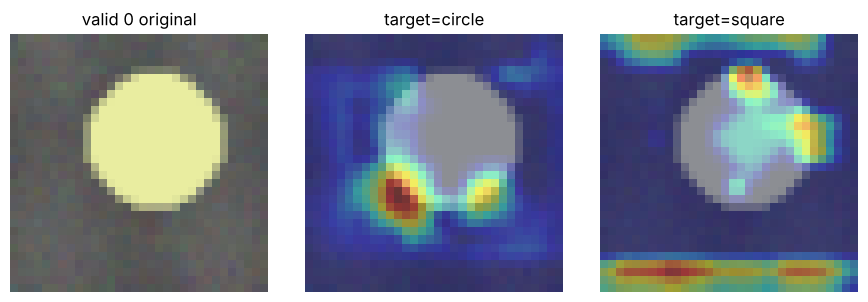

두 CAM 평균 절대 차이: 0.2794


In [6]:
# 원본 / circle 지도 / square 지도 비교 (BGR -> RGB로 바꿔 표시)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(X_valid[index].permute(1, 2, 0)); axes[0].set_title("valid 0 original")
for k, t in enumerate([0, 1], start=1):
    axes[k].imshow(cv2.cvtColor(overlays[t], cv2.COLOR_BGR2RGB))
    axes[k].set_title(f"target={valid.classes[t]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 두 지도가 실제로 다른지 수치로 확인
print("두 CAM 평균 절대 차이:", round(float(np.abs(cams[0] - cams[1]).mean()), 4))

## 정리 · README 정답 예와 대조

README 정답 실행 예: `target: circle logit: 1.5821 mean CAM: 0.1275`, `target: square logit: -1.351 mean CAM: 0.1719`.

- **Heatmap의 target:** 미분한 logit의 클래스다. 여기서는 예측 결과와 상관없이 target=0(circle), target=1(square)을 직접 지정했다.
- **target이 바뀌면 지도가 달라지는가?** 달라질 수 있다. 채널 가중치가 target logit의 gradient로 정해지므로, 같은 features라도 target마다 다른 채널이 양으로 기여한다. square logit이 음수여도 그 logit을 키우는 쪽으로 반응한 위치가 표시된다.
- **주의:** Grad-CAM은 반응 지도일 뿐 원인·정답 위치가 아니다. `inference_mode()` 안에서는 계산하지 않는다.